Question 1

We will be using python for numerically solving for and plotting Black-Scholes IV, as excel would require lots of inefficient goal seeks. We start by importing packages and loading the options data into a pandas dataframe and adding a tau column which is the annualised maturity.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
from scipy.optimize import least_squares

raw = pd.read_excel("AMZN_options.xlsx", sheet_name="options", header=None)

options = []

for col in range(1, 6):
    days = raw.iloc[1, col]
    strikes = raw.iloc[3:16, col]
    prices = raw.iloc[17:30, col]

    for strike, price in zip(strikes, prices):
        options.append({
            "days": days,
            "strike": strike,
            "price": price
        })

options = pd.DataFrame(options)
options["tau"] = options["days"]/365
options.head()

,days,strike,price,tau
0,14.0,230.0,30.62,0.038356
1,14.0,235.0,25.67,0.038356
2,14.0,240.0,20.87,0.038356
3,14.0,245.0,16.25,0.038356
4,14.0,250.0,11.94,0.038356


We define the Black-Scholes formula for a call option and let it return the price of the option given parameters. We will use this function when solving for the IV numerically.

In [25]:
def bs_call(S, K, r, tau, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)

    return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)


We also define the function that numerically solves for and returns the IV that makes C_modelprice - C_marketprice = 0.

We use SciPy's brentq to solve for IV, giving it an interval of [0.01%;300%] in annual volatility.

In [26]:
def implied_vol(S, K, r, tau, price):
    def pricing_error(sigma):
        return bs_call(S, K, r, tau, sigma) - price

    return brentq(pricing_error, 0.0001, 3.0)

We run a first test and get an IV of sigma=0.335 which seems reasonable.

If we plug this into our Black-Scholes function we should expect to get back the observed market price. Rounded to two decimals we get exactly the same price, so we conclude that our code works.

In [27]:
S=260
r=0.05
test = options.iloc[0]
iv = implied_vol(S, test["strike"], r, test["tau"],test["price"])
print(iv)

model_price = bs_call(S, test["strike"], r, test["tau"], iv)
print(f"Model price: {model_price:.2f}, market price: {test["price"]}")

0.33539714429219303
Model price: 30.62, market price: 30.62


Do the same for all option maturities and strikes and add list to options dataframe. We also define the forward price which is simply the cost of carrying the stock at r=5% and the log-moneyness

In [28]:
ivs = []

for _, option in options.iterrows():
    iv = implied_vol(
        S, option["strike"], r, option["tau"], option["price"]
    )
    ivs.append(iv)

options["iv"] = ivs
options.head()

,days,strike,price,tau,iv
0,14.0,230.0,30.62,0.038356,0.335397
1,14.0,235.0,25.67,0.038356,0.296830
2,14.0,240.0,20.87,0.038356,0.280666
3,14.0,245.0,16.25,0.038356,0.266925
4,14.0,250.0,11.94,0.038356,0.254658


In [29]:
options["forward"] = S * np.exp(r * options["tau"])
options["log_moneyness"] = np.log(options["strike"] / options["forward"])

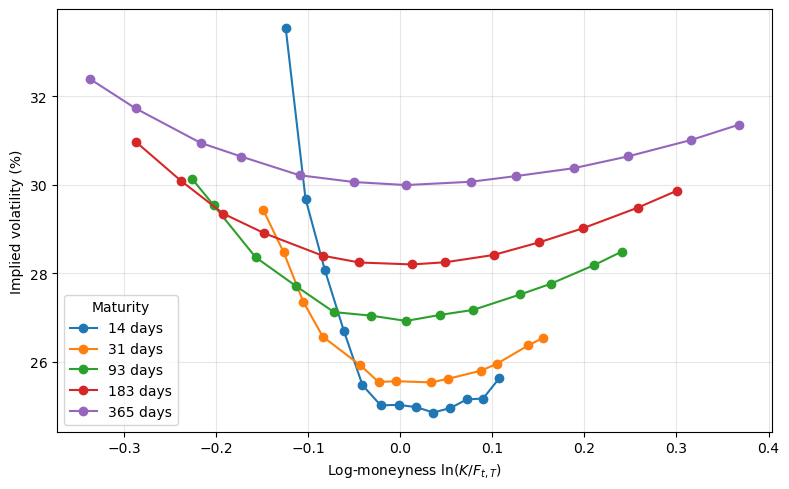

In [30]:
plt.figure(figsize=(8, 5))

for days, group in options.groupby("days"):
    group = group.sort_values("log_moneyness")
    plt.plot(
        group["log_moneyness"],
        100 * group["iv"],
        marker="o",
        label=f"{int(days)} days"
    )

plt.xlabel(r"Log-moneyness $\ln(K/F_{t,T})$")
plt.ylabel("Implied volatility (%)")
plt.legend(title="Maturity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

We plot the IV per maturity and log-moneyness and observe various volatility smiles.

We notice that ITM call options are more expensive than a constant volatility Black-Scholes model would suggest. This means the market prices large price decreases as more likely than BS does, i.e. the left tail of the return distribution is fatter than under the lognormal distribution, which weights extreme scenarios less than we observe empirically. OTM calls are also somewhat more expensive, since a deep OTM call would need a very large increase in price to have a positive payoff, but the left wing is steeper than the right, so the smile is skewed towards low strikes.

We also notice that the shorter the maturity, the steeper the smile. For longer maturities this is best explained by e.g. volatility being stochastic and for very short maturities with very steep smiles this is best explained by jumps which can produce discontinuous price moves. If the market believes these models are more realistic it would show up in IV in the observed way.

We need to compute the BS deltas and vegas, and plot them as a function of log-moneyness for each maturity. For a call option on a non-dividend underlying, they are computed as
* delta: $\Delta^{call}=N(d_1)$
* vega: $\nu^{call}=S_t\phi(d_1)\sqrt{\tau}$

We define the functions that calculate these selected greeks

In [31]:
def bs_d1(S, K, r, tau, sigma):
    return (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))

def bs_delta(S, K, r, tau, sigma):
    d1 = bs_d1(S, K, r, tau, sigma)
    return norm.cdf(d1)

def bs_vega(S, K, r, tau, sigma):
    d1 = bs_d1(S, K, r, tau, sigma)
    return S * norm.pdf(d1) * np.sqrt(tau)

we calculate delta and vega for all options in the df, using the IVs as sigma input

In [32]:
options['delta'] = bs_delta(S, options['strike'], r, options['tau'], options['iv'])
options['vega'] = bs_vega(S, options['strike'], r, options['tau'], options['iv'])

options.head()

,days,strike,price,tau,iv,forward,log_moneyness,delta,vega
0,14.0,230.0,30.62,0.038356,0.335397,260.499109,-0.124520,0.973104,3.163700
1,14.0,235.0,25.67,0.038356,0.296830,260.499109,-0.103014,0.964156,4.012249
2,14.0,240.0,20.87,0.038356,0.280666,260.499109,-0.081961,0.935562,6.412964
3,14.0,245.0,16.25,0.038356,0.266925,260.499109,-0.061341,0.884841,9.893484
4,14.0,250.0,11.94,0.038356,0.254658,260.499109,-0.041139,0.802278,14.157656


We plot the delta and vega as functions of log-moneyness for the respective maturities

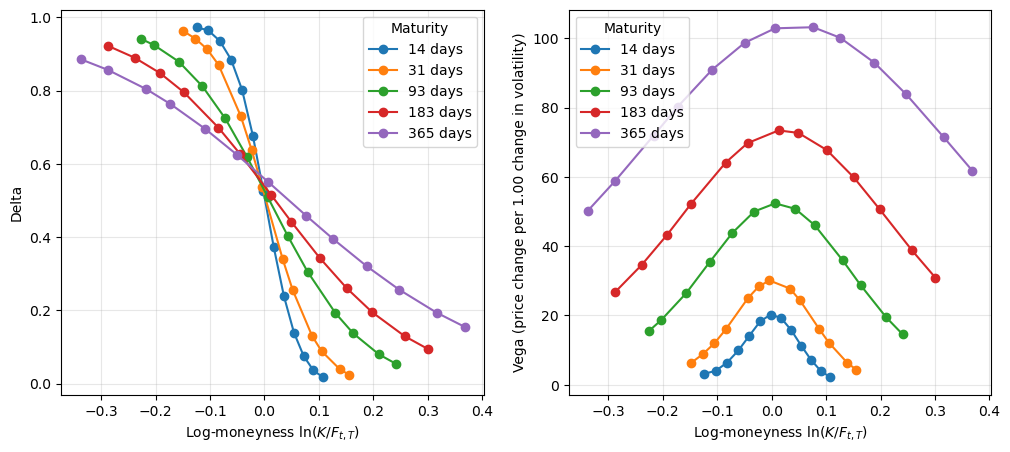

In [33]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5))

for days, group in options.groupby('days'):
    group = group.sort_values('log_moneyness')
    axes[0].plot(
        group['log_moneyness'],
        group['delta'],
        marker = 'o',
        label = f'{int(days)} days'
    )
    axes[1].plot(
        group['log_moneyness'],
        group['vega'],
        marker = 'o',
        label = f'{int(days)} days'
    )

axes[0].set_ylabel('Delta')
axes[1].set_ylabel('Vega (price change per 1.00 change in volatility)')
for ax in axes:
    ax.set_xlabel(r'Log-moneyness $\ln(K/F_{t,T})$')
    ax.grid(alpha = 0.3)
    ax.legend(title = 'Maturity')

plt.tight_layout
plt.show()

Delta is the sensitivity of the option price to the price of the underlying. It is positive across the whole grid, since $C_t^{BS}$ is strictly increasing in $S_t$. Intuitively, an increasing price of the underlying will only make a call option closer to being, or being further into, ITM territory. Delta falls from close to 1 for deep ITM calls to close to 0 for deep OTM calls. The transition is much steeper for short maturities, since there is little time for the stock price to cross the strike, meaning smaller movements in the underlying decide if it finishes above or below the strike.

Vega is the sensitivity of the option price to the volatility of the underlying, measured per unit change in $\sigma$. It is hump-shaped in log-moneyness, with its peak close to ATM strikes, where the outcome of the option is most uncertain. Vega is always positive, since $C_t^{BS}$ is strictly increasing in $\sigma$. Intuitively, an option holder benefits from higher volatility, since it makes large movements in both directions more likely. Potential gains from large upward movements outweigh the potential loss from large downward swings, which is limited to the option premium. This effect is largest for near ATM options, where small movements in the stock, helped on by larger volatility, decide whether the option expires with the underlying above the strike. Deep ITM and deep OTM options have low vega, since they are almost certain to finish in or out of the money regardless of a change in volatility. Vega is ceteris paribus increasing in maturity, since longer maturities give volatility more time to work. The same idea makes the humps wider with maturity, since strikes far from today's price are still reachable, as opposed to when time to expiration is short, and only strikes close to the money are in play.

Question 2

We will calibrate the Heston model to the AMZN IV surface. Rather than calibrating directly to the IVs, we calibrate to option prices scaled by their vegas. We build the Heston call price function using the Heston characteristic function and Fourier transform to get $\Pi_1$ and $\Pi_2$ in the generic pricing formula for European call option. When defining the characteristic function, we watch out for the Heston trap replace d by -d throughout.

In [36]:
##starting parameter values for integrand plots
kappa = 3
theta = 0.10
rho = -0.20
sigma_v = 1
v0 = 0.10

##Heston characteristic function
def heston_char(S, r, tau, kappa, rho, theta, sigma_v, v0, u):
    d = np.sqrt((rho*sigma_v*u*1j - kappa)**2 + sigma_v**2 * (u * 1j + u**2))
    d = -d ##the Heston trap
    g = (kappa - rho*sigma_v*u*1j + d)/(kappa - rho*sigma_v*u*1j - d)
    N = ((kappa - rho*sigma_v*u*1j + d) / sigma_v**2) * ((1 - np.exp(d*tau))/(1 - g*np.exp(d*tau)))
    M = r*u*1j*tau + (kappa*theta/sigma_v**2) * ((kappa - rho*sigma_v*u*1j + d) * tau - 2*np.log(((1 - g*np.exp(d*tau))/(1 - g))))
    return np.exp(M + N*v0 + 1j*u*np.log(S))

##integrands
def integrand1(S, K, r, tau, kappa, rho, theta, sigma_v, v0, u):
    phi = heston_char(S, r, tau, kappa, rho, theta, sigma_v, v0, u - 1j)
    return np.real(np.exp(-1j*u*np.log(K)) * phi / (1j*u*S*np.exp(r*tau)))

def integrand2(S, K, r, tau, kappa, rho, theta, sigma_v, v0, u):
    phi = heston_char(S, r, tau, kappa, rho, theta, sigma_v, v0, u)
    return np.real(np.exp(-1j*u*np.log(K)) * phi / (1j*u))

We plot the integrands for each maturity, using the ATM strike, to assess a fair truncation point for the Gauss-Legendre numerical integration scheme

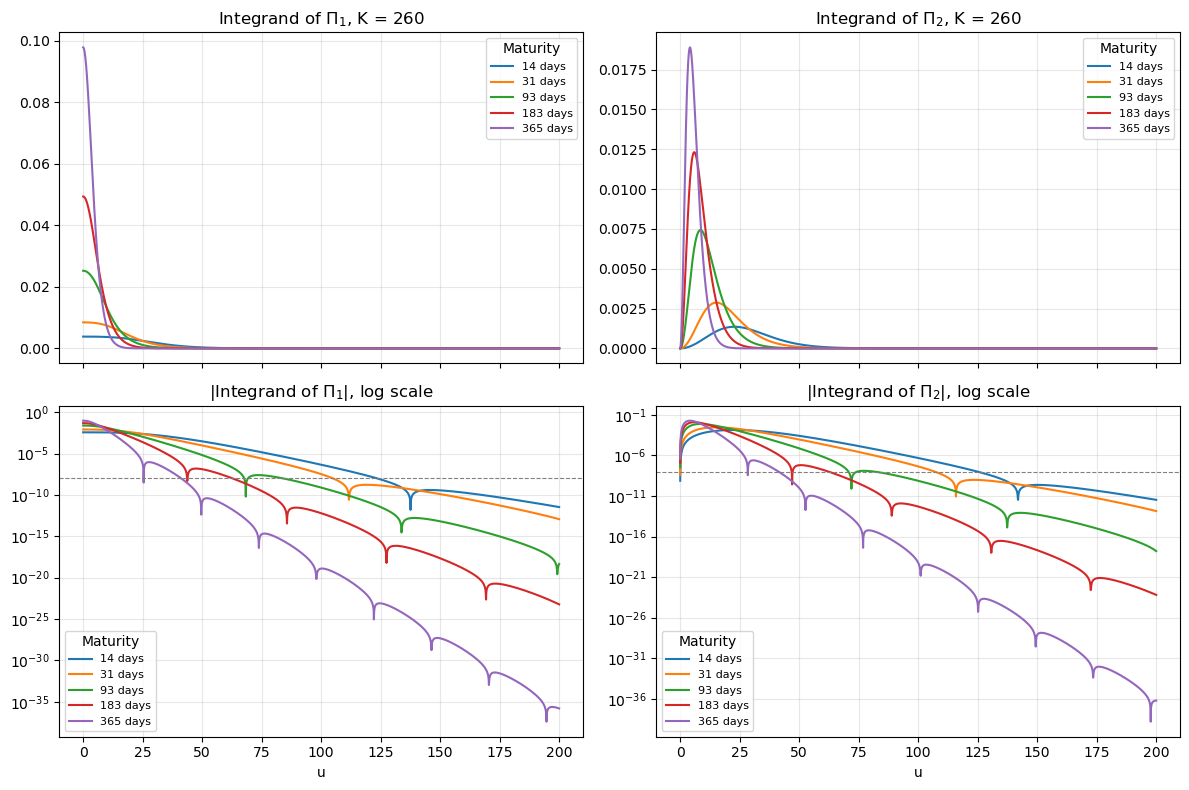

In [37]:

U = np.linspace(0.01, 200, 2000)
K = 260

##2x2 grid: top row linear scale, bottom row |integrand| on log scale
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for tau in options['tau'].unique():
    label = f'{round(tau*365)} days'
    i1 = integrand1(S, K, r, tau, kappa, rho, theta, sigma_v, v0, U)
    i2 = integrand2(S, K, r, tau, kappa, rho, theta, sigma_v, v0, U)
    axes[0, 0].plot(U, i1, label=label)
    axes[0, 1].plot(U, i2, label=label)
    axes[1, 0].semilogy(U, np.abs(i1), label=label)
    axes[1, 1].semilogy(U, np.abs(i2), label=label)

axes[0, 0].set_title(r'Integrand of $\Pi_1$, K = 260')
axes[0, 1].set_title(r'Integrand of $\Pi_2$, K = 260')
axes[1, 0].set_title(r'$|$Integrand of $\Pi_1|$, log scale')
axes[1, 1].set_title(r'$|$Integrand of $\Pi_2|$, log scale')
for ax in axes[1]:
    ax.axhline(1e-8, color='grey', ls='--', lw=0.8)
    ax.set_xlabel('u')
for ax in axes.flat:
    ax.grid(alpha=0.3)
    ax.legend(title='Maturity', fontsize=8)
plt.tight_layout()
plt.show()

The plots suggest a reasonable truncation for the Gauss-Legendre integration scheme around u = 150 for the starting parameters. Since the optimizer will try other parameters, we choose 200 as the truncation point to be prudent. We now continue with setting up the integration helper, the pricing function, and the optimizer. We optimize using the least squares method on the fitte vega-scaled price residual, settting bounds for variables, $\kappa, \theta, \sigma, v, \in [0, \infty)$ and $\rho \in [-1, 1$]

In [ ]:
##Gauss-Legendre integration scheme
def gl_integration(xmax, n):
    x, w = np.polynomial.legendre.leggauss(n)
    u = (x + 1) * xmax / 2
    w = w * xmax / 2
    return u, w

u, w = gl_integration(200, 100)

##Heston call price
def heston_call(S, K, r, tau, kappa, rho, theta, sigma_v, v0, u, w):
    Pi1 = 0.5 + np.sum(w * integrand1(S, K, r, tau, kappa, rho, theta, sigma_v, v0, u)) / np.pi
    Pi2 = 0.5 + np.sum(w * integrand2(S, K, r, tau, kappa, rho, theta, sigma_v, v0, u)) / np.pi
    return S * Pi1 - K * np.exp(-r * tau) * Pi2

##vega-scaled pricing errors
def residuals(params):
    kappa, theta, rho, sigma_v, v0 = params
    errors = []
    for o in options.itertuples():
        model_price = heston_call(S, o.strike, r, o.tau, kappa, rho, theta, sigma_v, v0, u, w)
        errors.append((model_price - o.price) / o.vega)
    return np.array(errors)

##minimize the sum of squared errors, starting from the given values
x0 = [3, 0.10, -0.20, 1, 0.10]
res = least_squares(residuals, x0, bounds=([0, 0, -1, 0, 0], [np.inf, np.inf, 1, np.inf, np.inf]))
kappa_c, theta_c, rho_c, sigma_v_c, v0_c = res.x
print(res.x)

[ 3.4271238   0.11258757 -0.10256794  0.87299464  0.06203279]


Comments:

With the estimated parameters, we can now fit the Heston IV surface, and plot the IV smile for each maturity against the market IVs at each maturity.

In [8]:
options['price_heston'] = [heston_call(S, o.strike, r, o.tau, kappa_c, rho_c, theta_c, sigma_v_c, v0_c, u, w)
                           for o in options.itertuples()]
options['iv_heston'] = [implied_vol(S, o.strike, r, o.tau, o.price_heston)
                        for o in options.itertuples()]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (days, group) in zip(axes.flat, options.groupby('days')):
    group = group.sort_values('log_moneyness')
    ax.plot(group['log_moneyness'], 100*group['iv'], 'o', label='Market')
    ax.plot(group['log_moneyness'], 100*group['iv_heston'], '-', label='Heston')
    ax.set_title(f'{int(days)} days')
    ax.set_xlabel(r'Log-moneyness $\ln(K/F_{t,T})$')
    ax.set_ylabel('Implied volatility (%)')
    ax.grid(alpha=0.3)
    ax.legend()
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

NameError: name 'heston_call' is not defined

Comments: 

Question 3.1

We simulate six months using 126 daily steps of length $1/252$. At every step, we generate 50,000 independent shock pairs and append their negatives, giving 100,000 paths with antithetic variates. The variance state follows the full-truncation Euler scheme: the raw variance is retained in the path, while $v_t^+=\max(v_t,0)$ is used in the variance drift, variance diffusion, and stock-price update. This avoids taking the square root of a negative variance while preserving the full-truncation update.

The first plot compares the simulated distribution of $\log(S_T)$ with a normal density having the same sample mean and standard deviation. The second shows terminal variance, clipping negative raw Euler values to zero for display. Keep `S_paths` and `v_paths` unchanged for the later questions; whenever a subsequent calculation requires a nonnegative variance, use `np.maximum(v_paths, 0)`. The fixed random seed makes the simulation reproducible.

Paths: 100,000 (50,000 antithetic pairs)
Time steps: 126; horizon: 0.500000 years
Negative raw terminal variance values: 0.12%
Mean and standard deviation of log(S_T): 5.562789, 0.218286


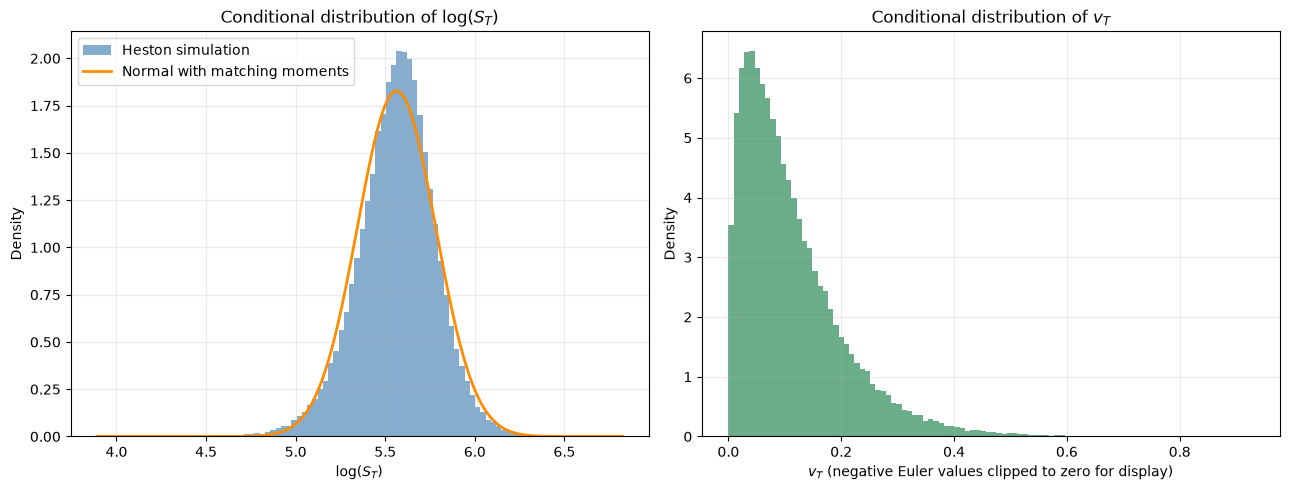

In [7]:
# Question 3.1: Heston paths using full-truncation Euler and antithetic variates
S0 = 260.0
r = 0.05
kappa, theta, rho, sigma_v, v0 = 4.0, 0.12, -0.15, 0.80, 0.06
dt = 1 / 252
n_steps = 126
n_paths = 100_000
seed = 1

rng = np.random.default_rng(seed)
n_pairs = n_paths // 2
S_paths = np.empty((n_paths, n_steps + 1), dtype=float)
v_paths = np.empty_like(S_paths)
S_paths[:, 0] = S0
v_paths[:, 0] = v0

for step in range(n_steps):
    z_s_half = rng.standard_normal(n_pairs)
    z_perp_half = rng.standard_normal(n_pairs)
    z_s = np.concatenate((z_s_half, -z_s_half))
    z_perp = np.concatenate((z_perp_half, -z_perp_half))
    z_v = rho * z_s + np.sqrt(1 - rho**2) * z_perp

    v_current = v_paths[:, step]
    v_positive = np.maximum(v_current, 0.0)
    v_paths[:, step + 1] = (
        v_current
        + kappa * (theta - v_positive) * dt
        + sigma_v * np.sqrt(v_positive * dt) * z_v
    )
    S_paths[:, step + 1] = S_paths[:, step] * np.exp(
        (r - 0.5 * v_positive) * dt
        + np.sqrt(v_positive * dt) * z_s
    )

T = n_steps * dt
log_ST = np.log(S_paths[:, -1])
log_ST_mean = log_ST.mean()
log_ST_std = log_ST.std(ddof=1)
vT_for_plot = np.maximum(v_paths[:, -1], 0.0)

print(f"Paths: {n_paths:,} ({n_pairs:,} antithetic pairs)")
print(f"Time steps: {n_steps}; horizon: {T:.6f} years")
print(f"Negative raw terminal variance values: {(v_paths[:, -1] < 0).mean():.2%}")
print(f"Mean and standard deviation of log(S_T): {log_ST_mean:.6f}, {log_ST_std:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.linspace(log_ST.min(), log_ST.max(), 500)
axes[0].hist(log_ST, bins=100, density=True, alpha=0.65, color="steelblue", label="Heston simulation")
axes[0].plot(x, norm.pdf(x, loc=log_ST_mean, scale=log_ST_std), color="darkorange", lw=2, label="Normal with matching moments")
axes[0].set_title(r"Conditional distribution of $\log(S_T)$")
axes[0].set_xlabel(r"$\log(S_T)$")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].hist(vT_for_plot, bins=100, density=True, alpha=0.7, color="seagreen")
axes[1].set_title(r"Conditional distribution of $v_T$")
axes[1].set_xlabel(r"$v_T$ (negative Euler values clipped to zero for display)")
axes[1].set_ylabel("Density")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [10]:
# Question 3.2: moments of the simulated terminal distributions
log_ST_values = np.log(S_paths[:, -1])
vT_values = np.maximum(v_paths[:, -1], 0.0)

statistics = []
for distribution, values in {
    "log(S_T)": log_ST_values,
    "v_T (clipped at zero)": vT_values,
}.items():
    centered = values - np.mean(values)
    second_moment = np.mean(centered**2)
    statistics.append({
        "Distribution": distribution,
        "Mean": np.mean(values),
        "Median": np.median(values),
        "Skewness": np.mean(centered**3) / second_moment**1.5,
        "Kurtosis (Pearson)": np.mean(centered**4) / second_moment**2,
    })

summary_32 = pd.DataFrame(statistics).set_index("Distribution")
print(f"Raw v_T values clipped to zero: {(v_paths[:, -1] < 0).mean():.2%}")
summary_32

Raw v_T values clipped to zero: 0.12%


,Mean,Median,Skewness,Kurtosis (Pearson)
Distribution,,,,
log(S_T),5.562789,5.573271,-0.305607,4.071977
v_T (clipped at zero),0.111972,0.088472,1.620329,6.963572


We report Pearson kurtosis, $m_4/m_2^2$, so a normal distribution has kurtosis 3 (excess kurtosis would subtract 3). The statistics use the simulated log prices and nonnegative terminal variances; 0.12% of the raw Euler terminal variance values were negative and are clipped to zero, consistent with the plot.

The distribution of $\log(S_T)$ is mildly left-skewed: its mean is below its median and its skewness is negative. This is consistent with the negative correlation between stock and variance shocks: negative stock moves tend to coincide with rising variance. Its kurtosis exceeds 3, indicating heavier tails than a normal distribution with the same variance.

Terminal variance is substantially right-skewed: its mean exceeds its median, and its positive skewness and high kurtosis reflect occasional high-variance outcomes. Its mean has risen from the initial variance $v_0=0.06$ toward the long-run level $\theta=0.12$, as mean reversion predicts.

Question 3.3

We price the European put by discounting its terminal payoff on the simulated paths. Because the paths were generated in antithetic pairs, the confidence interval uses the 50,000 pair-average payoffs as independent observations. As a benchmark, we compute the Heston call price by Fourier integration of the characteristic function, then obtain the put price using put-call parity. The benchmark uses the fixed simulation parameters, not the calibrated parameters from Question 2.

In [30]:
# Monte Carlo estimate, with the antithetic pairs as the independent observations
K_put = 270.0
S_T = S_paths[:, -1]
discounted_payoffs = np.exp(-r * T) * np.maximum(K_put - S_T, 0.0)
pair_payoffs = 0.5 * (discounted_payoffs[:n_pairs] + discounted_payoffs[n_pairs:])
put_mc = pair_payoffs.mean()
put_mc_se = pair_payoffs.std(ddof=1) / np.sqrt(n_pairs)
put_mc_ci = (put_mc - 1.96 * put_mc_se, put_mc + 1.96 * put_mc_se)

# Characteristic-function benchmark under the Question 3 Heston parameters
kappa_33, theta_33, rho_33, sigma_v_33, v0_33 = 4.0, 0.12, -0.15, 0.80, 0.06

def heston_cf_33(u):
    d = np.sqrt(
        (rho_33 * sigma_v_33 * 1j * u - kappa_33) ** 2
        + sigma_v_33**2 * (1j * u + u**2)
    )
    d = -d
    g = (kappa_33 - rho_33 * sigma_v_33 * 1j * u + d) / (
        kappa_33 - rho_33 * sigma_v_33 * 1j * u - d
    )
    exp_dt = np.exp(d * T)
    D = ((kappa_33 - rho_33 * sigma_v_33 * 1j * u + d) / sigma_v_33**2) * (
        (1 - exp_dt) / (1 - g * exp_dt)
    )
    C = r * 1j * u * T + (kappa_33 * theta_33 / sigma_v_33**2) * (
        (kappa_33 - rho_33 * sigma_v_33 * 1j * u + d) * T
        - 2 * np.log((1 - g * exp_dt) / (1 - g))
    )
    return np.exp(C + D * v0_33 + 1j * u * np.log(S0))

n_quad = 256
u_max = 200.0
gl_nodes, gl_weights = np.polynomial.legendre.leggauss(n_quad)
u_nodes = (gl_nodes + 1) * u_max / 2
quad_weights = gl_weights * u_max / 2

phi_1 = heston_cf_33(u_nodes - 1j)
phi_2 = heston_cf_33(u_nodes)
integrand_1 = np.real(
    np.exp(-1j * u_nodes * np.log(K_put))
    * phi_1
    / (1j * u_nodes * S0 * np.exp(r * T))
)
integrand_2 = np.real(
    np.exp(-1j * u_nodes * np.log(K_put))
    * phi_2
    / (1j * u_nodes)
)
prob_1 = 0.5 + np.dot(quad_weights, integrand_1) / np.pi
prob_2 = 0.5 + np.dot(quad_weights, integrand_2) / np.pi
call_cf = S0 * prob_1 - K_put * np.exp(-r * T) * prob_2
put_cf = call_cf - S0 + K_put * np.exp(-r * T)

inside_ci = put_mc_ci[0] <= put_cf <= put_mc_ci[1]
print(f"Monte Carlo put estimate: {put_mc:.6f}")
print(f"Monte Carlo standard error (pair-based): {put_mc_se:.6f}")
print(f"95% confidence interval: [{put_mc_ci[0]:.6f}, {put_mc_ci[1]:.6f}]")
print(f"Heston characteristic-function put price: {put_cf:.6f}")
print(f"Characteristic-function price inside CI: {inside_ci}")

Monte Carlo put estimate: 23.271917
Monte Carlo standard error (pair-based): 0.069821
95% confidence interval: [23.135067, 23.408766]
Heston characteristic-function put price: 23.415346
Characteristic-function price inside CI: False


The simulated put price is $23.2719$, with a 95% confidence interval of $[23.1351, 23.4088]$. The characteristic-function benchmark is $23.4153$, just $0.0066$ above the upper confidence limit, so it is not inside this particular interval. The interval quantifies Monte Carlo sampling uncertainty for the discretely simulated paths; it does not include bias from approximating continuous-time Heston dynamics with daily full-truncation Euler steps. That time-discretization error is the likely source of a systematic difference. Since the miss is very small relative to the interval width, ordinary sampling variation can also explain this single 95% interval miss.